# Day 5: Linear Regression
<span style="display: inline-block; background-color: rgba(25, 25, 112, 0.25); color: #00FFFF; padding: 4px 12px; border-radius: 9999px; font-size: 13px; font-weight: 600; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; border: 1px solid rgba(25, 25, 112, 0.5);">Supervised Learning · Regression
</span><br>
<br>

Welcome to Day 5! Today we'll study **Linear Regression** in depth, including its mathematical foundation, how Scikit-learn learns the regression equation, and how to interpret predictions.

In Day 4, we compared Linear Regression and Decision Tree Regression. Linear Regression performed better on your house-price dataset. Today, we'll understand exactly how that model works.

## Today's learning objectives:
1. What Linear Regression is.
2. Simple Linear Regression vs Multiple Linear Regression.
3. The mathematical equation of a regression line.
4. Slope and intercept.
5. How the model learns coefficients using the least squares method.
6. How to interpret `coef_` and `intercept_`.
7. Predictions and residuals.
8. Visualizing regression using Matplotlib.
9. Evaluating Linear Regression using MAE, MSE, RMSE and R².

## Part 1 — What is Linear Regression?
### 1. Explanation
Linear Regression is a supervised machine learning algorithm used to predict a continuous numerical value.

Examples:
- Predicting house prices.
- Predicting student marks.
- Predicting monthly sales.
- Predicting employee salaries.
- Predicting temperature.

The algorithm learns the relationship between input features and a numerical target.

For example:
| Study hours | Marks |
| :--- | :--- |
| 1 | 30 |
| 2 | 40 |
| 3 | 50 |
| 4 | 60 |
| 5 | 70 |

We can observe that marks increase as study hours increase.

Linear Regression attempts to learn this relationship mathematically.

### 2. How does it work?
It tries to find a straight line that best represents the relationship between the input and output values.

In [1]:

from IPython.display import HTML

html_code = """
<div id="vis-container" style="background-color: #0c0c0e; color: #f3f4f6; padding: 20px; border-radius: 12px; border: 1px solid #27272a; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; max-width: 480px; margin: 0 auto; box-sizing: border-box; user-select: none;">

  <!-- Equation Display -->
  <div style="text-align: center; margin-bottom: 16px;">
    <div style="font-size: 16px; font-weight: 600; font-style: italic; margin-bottom: 6px;" id="eq-general">y&#770; = b<sub>0</sub> + b<sub>1</sub>x</div>
    <div style="font-size: 18px; font-weight: 700; font-style: italic; color: #f3f4f6; margin-bottom: 4px;" id="eq-fitted">y&#770; = 8.49 &minus; 0.54x</div>
    <div style="font-size: 12px; color: #a1a1aa; font-style: italic;" id="metrics-text">Estimated intercept &middot; R-squared = 0.72</div>
  </div>

  <!-- Fit Toggle -->
  <div style="display: flex; align-items: center; margin-bottom: 12px; font-size: 13px;">
    <span style="width: 60px; color: #a1a1aa;">Fit</span>
    <div style="display: flex; background-color: #18181b; border: 1px solid #27272a; border-radius: 9999px; padding: 3px; flex-grow: 1;">
      <button onclick="setFit('intercept')" id="btn-intercept" style="flex: 1; background-color: #f3f4f6; color: #0c0c0e; border: none; border-radius: 9999px; padding: 6px 0; font-size: 12px; font-weight: 600; cursor: pointer; transition: all 0.2s;">Intercept</button>
      <button onclick="setFit('origin')" id="btn-origin" style="flex: 1; background-color: transparent; color: #a1a1aa; border: none; border-radius: 9999px; padding: 6px 0; font-size: 12px; font-weight: 600; cursor: pointer; transition: all 0.2s;">Through origin</button>
    </div>
  </div>

  <!-- Focus Toggle -->
  <div style="display: flex; align-items: center; margin-bottom: 16px; font-size: 13px;">
    <span style="width: 60px; color: #a1a1aa;">Focus</span>
    <div style="display: flex; background-color: #18181b; border: 1px solid #27272a; border-radius: 9999px; padding: 3px; flex-grow: 1;">
      <button onclick="setFocus('data')" id="btn-focus-data" class="focus-btn" style="flex: 1; background-color: #f3f4f6; color: #0c0c0e; border: none; border-radius: 9999px; padding: 6px 0; font-size: 11px; font-weight: 600; cursor: pointer;">Data</button>
      <button onclick="setFocus('line')" id="btn-focus-line" class="focus-btn" style="flex: 1; background-color: transparent; color: #a1a1aa; border: none; border-radius: 9999px; padding: 6px 0; font-size: 11px; font-weight: 600; cursor: pointer;">Line</button>
      <button onclick="setFocus('predictions')" id="btn-focus-predictions" class="focus-btn" style="flex: 1; background-color: transparent; color: #a1a1aa; border: none; border-radius: 9999px; padding: 6px 0; font-size: 11px; font-weight: 600; cursor: pointer;">Predictions</button>
      <button onclick="setFocus('residuals')" id="btn-focus-residuals" class="focus-btn" style="flex: 1; background-color: transparent; color: #a1a1aa; border: none; border-radius: 9999px; padding: 6px 0; font-size: 11px; font-weight: 600; cursor: pointer;">Residuals</button>
    </div>
  </div>

  <!-- Generate New Data Button -->
  <div style="text-align: center; margin-bottom: 16px;">
    <button onclick="generateNewData()" style="background-color: #18181b; color: #f3f4f6; border: 1px solid #3f3f46; border-radius: 8px; padding: 8px 16px; font-size: 13px; font-weight: 600; cursor: pointer; width: 100%;">Generate new data</button>
  </div>

  <!-- Plot Container -->
  <div style="background-color: #121215; border: 1px solid #27272a; border-radius: 10px; padding: 12px; position: relative;">
    <div style="font-size: 11px; color: #a1a1aa; margin-bottom: 6px;">Drag a point to refit the line.</div>
    <div style="font-weight: 700; font-size: 14px; margin-bottom: 4px; color: #f3f4f6;">Response</div>
    
    <canvas id="regCanvas" width="430" height="300" style="display: block; cursor: crosshair; width: 100%; height: auto;"></canvas>
    
    <div style="text-align: center; font-weight: 700; font-size: 13px; color: #f3f4f6; margin-top: 6px;">Predictor</div>
  </div>

</div>

<script>
(function() {
  const canvas = document.getElementById('regCanvas');
  if (!canvas) return;
  const ctx = canvas.getContext('2d');

  let fitMode = 'intercept'; // 'intercept' or 'origin'
  let focusMode = 'data';    // 'data', 'line', 'predictions', 'residuals'

  // Initial Data Points
  let points = [
    {x: 1.2, y: 7.5},
    {x: 1.8, y: 8.6},
    {x: 2.6, y: 6.1},
    {x: 3.4, y: 7.7},
    {x: 4.4, y: 5.3},
    {x: 5.4, y: 6.2},
    {x: 6.1, y: 4.2},
    {x: 7.3, y: 5.6},
    {x: 8.1, y: 3.3},
    {x: 8.9, y: 4.1}
  ];

  let draggingIndex = null;
  const xMin = 0, xMax = 10;
  const yMin = 0, yMax = 10;

  function toScreenX(x) {
    return 45 + (x - xMin) / (xMax - xMin) * (canvas.width - 65);
  }
  function toScreenY(y) {
    return canvas.height - 35 - (y - yMin) / (yMax - yMin) * (canvas.height - 55);
  }
  function toDataX(sx) {
    return xMin + (sx - 45) / (canvas.width - 65) * (xMax - xMin);
  }
  function toDataY(sy) {
    return yMin + (canvas.height - 35 - sy) / (canvas.height - 55) * (yMax - yMin);
  }

  window.setFit = function(mode) {
    fitMode = mode;
    document.getElementById('btn-intercept').style.backgroundColor = mode === 'intercept' ? '#f3f4f6' : 'transparent';
    document.getElementById('btn-intercept').style.color = mode === 'intercept' ? '#0c0c0e' : '#a1a1aa';
    document.getElementById('btn-origin').style.backgroundColor = mode === 'origin' ? '#f3f4f6' : 'transparent';
    document.getElementById('btn-origin').style.color = mode === 'origin' ? '#0c0c0e' : '#a1a1aa';
    draw();
  };

  window.setFocus = function(mode) {
    focusMode = mode;
    document.querySelectorAll('.focus-btn').forEach(btn => {
      btn.style.backgroundColor = 'transparent';
      btn.style.color = '#a1a1aa';
    });
    const activeBtn = document.getElementById('btn-focus-' + mode);
    if (activeBtn) {
      activeBtn.style.backgroundColor = '#f3f4f6';
      activeBtn.style.color = '#0c0c0e';
    }
    draw();
  };

  window.generateNewData = function() {
    points = points.map(p => {
      let nx = p.x + (Math.random() - 0.5) * 0.4;
      let ny = 8.5 - 0.5 * nx + (Math.random() - 0.5) * 1.8;
      return {
        x: Math.max(0.5, Math.min(9.5, nx)),
        y: Math.max(1, Math.min(9.5, ny))
      };
    });
    draw();
  };

  function computeRegression() {
    let n = points.length;
    let sumX = 0, sumY = 0, sumXY = 0, sumX2 = 0;
    points.forEach(p => {
      sumX += p.x;
      sumY += p.y;
      sumXY += p.x * p.y;
      sumX2 += p.x * p.x;
    });

    let b0 = 0, b1 = 0;
    if (fitMode === 'intercept') {
      let meanX = sumX / n;
      let meanY = sumY / n;
      let num = 0, den = 0;
      points.forEach(p => {
        num += (p.x - meanX) * (p.y - meanY);
        den += (p.x - meanX) * (p.x - meanX);
      });
      b1 = den !== 0 ? num / den : 0;
      b0 = meanY - b1 * meanX;
    } else {
      b1 = sumX2 !== 0 ? sumXY / sumX2 : 0;
      b0 = 0;
    }

    let ssTot = 0, ssRes = 0;
    let meanY = sumY / n;
    points.forEach(p => {
      let pred = b0 + b1 * p.x;
      ssTot += Math.pow(p.y - meanY, 2);
      ssRes += Math.pow(p.y - pred, 2);
    });
    let r2 = ssTot !== 0 ? Math.max(0, 1 - (ssRes / ssTot)) : 0;

    return { b0, b1, r2 };
  }

  function draw() {
    ctx.clearRect(0, 0, canvas.width, canvas.height);

    // Grid lines & Axis labels
    ctx.strokeStyle = '#27272a';
    ctx.lineWidth = 1;
    ctx.fillStyle = '#a1a1aa';
    ctx.font = '11px -apple-system, sans-serif';

    for (let yVal = 2; yVal <= 8; yVal += 2) {
      let sy = toScreenY(yVal);
      ctx.beginPath();
      ctx.moveTo(45, sy);
      ctx.lineTo(canvas.width - 20, sy);
      ctx.stroke();
      ctx.fillText(yVal, 20, sy + 4);
    }

    for (let xVal = 2; xVal <= 10; xVal += 2) {
      let sx = toScreenX(xVal);
      ctx.beginPath();
      ctx.moveTo(sx, 15);
      ctx.lineTo(sx, canvas.height - 35);
      ctx.stroke();
      ctx.fillText(xVal, sx - 6, canvas.height - 18);
    }

    // Axes
    ctx.strokeStyle = '#3f3f46';
    ctx.beginPath();
    ctx.moveTo(45, 15);
    ctx.lineTo(45, canvas.height - 35);
    ctx.lineTo(canvas.width - 20, canvas.height - 35);
    ctx.stroke();

    const { b0, b1, r2 } = computeRegression();

    // Update UI text
    let eqFittedStr = `y&#770; = ${b0.toFixed(2)} ${b1 >= 0 ? '+ ' + b1.toFixed(2) : '&minus; ' + Math.abs(b1).toFixed(2)}x`;
    if (fitMode === 'origin') {
      eqFittedStr = `y&#770; = ${b1.toFixed(2)}x`;
    }
    document.getElementById('eq-fitted').innerHTML = eqFittedStr;
    document.getElementById('metrics-text').innerHTML = `${fitMode === 'intercept' ? 'Estimated intercept' : 'Through origin'} &middot; R-squared = ${r2.toFixed(2)}`;

    // Residuals
    if (focusMode === 'residuals' || focusMode === 'line') {
      ctx.strokeStyle = 'rgba(59, 130, 246, 0.4)';
      ctx.setLineDash([2, 2]);
      points.forEach(p => {
        let predY = b0 + b1 * p.x;
        let sx = toScreenX(p.x);
        let sy1 = toScreenY(p.y);
        let sy2 = toScreenY(predY);
        ctx.beginPath();
        ctx.moveTo(sx, sy1);
        ctx.lineTo(sx, sy2);
        ctx.stroke();
      });
      ctx.setLineDash([]);
    }

    // Regression Line
    if (focusMode !== 'data') {
      ctx.strokeStyle = '#34d399';
      ctx.lineWidth = 2.5;
      ctx.beginPath();
      let xStart = xMin, xEnd = xMax;
      ctx.moveTo(toScreenX(xStart), toScreenY(b0 + b1 * xStart));
      ctx.lineTo(toScreenX(xEnd), toScreenY(b0 + b1 * xEnd));
      ctx.stroke();
    }

    // Predicted Points
    if (focusMode === 'predictions') {
      points.forEach(p => {
        let predY = b0 + b1 * p.x;
        let sx = toScreenX(p.x);
        let sy = toScreenY(predY);
        ctx.fillStyle = '#34d399';
        ctx.beginPath();
        ctx.arc(sx, sy, 5, 0, Math.PI * 2);
        ctx.fill();
        ctx.strokeStyle = '#ffffff';
        ctx.lineWidth = 1.5;
        ctx.stroke();
      });
    }

    // Data Points
    points.forEach((p, idx) => {
      let sx = toScreenX(p.x);
      let sy = toScreenY(p.y);
      
      ctx.fillStyle = '#3b82f6';
      ctx.beginPath();
      ctx.arc(sx, sy, 6, 0, Math.PI * 2);
      ctx.fill();
      
      if (idx === draggingIndex) {
        ctx.strokeStyle = '#ffffff';
        ctx.lineWidth = 2;
        ctx.stroke();
      }
    });
  }

  // Mouse Interactions
  canvas.addEventListener('mousedown', (e) => {
    const rect = canvas.getBoundingClientRect();
    const mouseX = e.clientX - rect.left;
    const mouseY = e.clientY - rect.top;

    points.forEach((p, idx) => {
      let sx = toScreenX(p.x);
      let sy = toScreenY(p.y);
      let dist = Math.hypot(mouseX - sx, mouseY - sy);
      if (dist < 12) {
        draggingIndex = idx;
      }
    });
  });

  canvas.addEventListener('mousemove', (e) => {
    if (draggingIndex !== null) {
      const rect = canvas.getBoundingClientRect();
      const mouseX = e.clientX - rect.left;
      const mouseY = e.clientY - rect.top;

      let newDataX = Math.max(xMin + 0.2, Math.min(xMax - 0.2, toDataX(mouseX)));
      let newDataY = Math.max(yMin + 0.2, Math.min(yMax - 0.2, toDataY(mouseY)));

      points[draggingIndex].x = newDataX;
      points[draggingIndex].y = newDataY;
      draw();
    }
  });

  window.addEventListener('mouseup', () => {
    draggingIndex = null;
  });

  // Initial draw call
  draw();
})();
</script>
"""

HTML(html_code)

The model finds a line that minimizes the sum of squared vertical differences between actual observations and predicted values.

### 3. Why is it called Linear Regression?
- **Linear:** It models a linear relationship between the target and the coefficients of the features.
- **Regression:** It predicts a continuous numerical value.

Remember: Linear Regression is a regression algorithm, not a classification algorithm.

## Part 2 — Simple Linear Regression
Simple Linear Regression uses **one independent variable (feature)** to predict one dependent variable (target).

For example:
- Input: Study hours.
- Output: Student marks.

### Mathematical equation
The equation of a straight line is: 
$$y = mx+c$$
In machine learning, we commonly write:
$$\hat{y}=b_0+b_1x$$

Where:
| Symbol | Meaning |
| :--- | :--- |
| $\hat{y}$ | Predicted output |
| $x$ | Input feature |
| $b_0$ | Intercept |
| $b_1$ | Coefficient or slope |

Let's understand these two important terms.

#### A. Slope (Coefficient)
The slope tells us how much the predicted output changes when the input increases by one unit.

For example:
$$\hat{y}=20+10x$$
Here, the slope is 10.

This means every additional study hour increases the predicted marks by 10, according to this model.

#### B. Intercept
The intercept represents the predicted output when the input is zero.

For the same equation:
$$\hat{y}=20+10x$$
When study hours = 0:
$$\hat{y}=20$$
Therefore, the predicted marks are 20.

Note that the intercept is a mathematical starting point; it doesn't necessarily have a meaningful real-world interpretation.

## Part 3 — Implement Simple Linear Regression using Scikit-learn
Now let's implement our first Linear Regression model.

### 1. Create a dataset
We'll use a student study-hours dataset.

**Code:**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "study_hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "marks": [30, 35, 45, 50, 55, 65, 70, 75, 85, 95]
})

df

,study_hours,marks
0,1,30
1,2,35
2,3,45
3,4,50
4,5,55
5,6,65
6,7,70
7,8,75
8,9,85
9,10,95


### 2. Separate features and target

In [3]:
X = df[["study_hours"]]
y = df["marks"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10, 1)
Target shape: (10,)


### 3. Train the model

In [4]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[7.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['study_hours']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,22
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


**What happens when we execute `fit()`?**
1. The model receives the input features and target values.
2. It searches for the best-fitting linear relationship.
3. It learns the coefficient and intercept.
4. It stores these learned parameters inside the model.

### 4. Extract coefficient and intercept

In [5]:
print("Coefficient:", model.coef_[0].round(2))
print("Intercept:", model.intercept_.round(2))

Coefficient: 7.0
Intercept: 22.0


Our dataset follows this relationship exactly:
$$\hat{y}=22+7x$$
**Interpretation:**
- Intercept = 22 marks.
- Coefficient = 7 marks per additional study hour.

### 5. Make predictions
Let's predict marks for students studying 4, 7, and 12 hours.

In [6]:
new_students = pd.DataFrame({
    "study_hours": [4, 7, 12]
})

predictions = model.predict(new_students)

for hours, marks in zip(new_students["study_hours"], predictions):
    print(f"Study hours: {hours}, Predicted marks: {marks:.2f}")

Study hours: 4, Predicted marks: 50.00
Study hours: 7, Predicted marks: 71.00
Study hours: 12, Predicted marks: 106.00


<span style="color: #FF3333; font-weight: bold; font-size: 20px">Important observation:</span><br>
The 12-hour prediction is outside the training data's range (1–10 hours). This is called extrapolation. The model can calculate the value, but we should be cautious because the learned relationship may not continue beyond the observed range. A prediction of 106 also exceeds the usual 100-mark scale.

## Part 4 — How does Linear Regression find the best line?
This is one of the most important concepts in today's lesson.

### 1. Actual vs predicted values
Suppose we have:
| Study hours | Actual marks | Predicted marks |
| :--- | :--- | :--- |
| 1 | 30 | 29 |
| 2 | 35 | 36 |
| 3 | 45 | 43 |

The model's predictions may not always exactly match the actual values.

The difference between an actual value and its predicted value is called a residual.

$$e_i=y_i-\hat{y}_i$$

For example, if:
- Actual marks = 45
- Predicted marks = 43
Then:

$$e=45-43=2$$

A positive residual means the model predicted too low. A negative residual means it predicted too high.

### 2. Least Squares Method
Linear Regression commonly learns its coefficients by minimizing the sum of squared residuals.

$$SSE=\sum_{i=1}^{n}(y_i-\hat{y}_i)^2$$

**Why square the residuals?**
1. Positive and negative errors cannot cancel each other out.
2. Larger errors receive greater penalties.
3. The squared-error objective has useful mathematical properties for finding the best-fitting linear coefficients.

The model searches for coefficients that minimize this quantity.

### 3. Calculate residuals using Python

In [7]:
predictions = model.predict(X)

results = df.copy()

results["predicted_marks"] = predictions
results["residuals"] = results["marks"] - results["predicted_marks"]

results

,study_hours,marks,predicted_marks,residuals
0,1,30,29.0,1.0
1,2,35,36.0,-1.0
2,3,45,43.0,2.0
3,4,50,50.0,0.0
4,5,55,57.0,-2.0
5,6,65,64.0,1.0
6,7,70,71.0,-1.0
7,8,75,78.0,-3.0
8,9,85,85.0,0.0
9,10,95,92.0,3.0


Now calculate the sum of squared errors:

In [8]:
sse = (results["residuals"] ** 2).sum()

print("Sum of Squared Errors:", sse)

Sum of Squared Errors: 30.0


## Part 5 — Visualize Linear Regression using Matplotlib
Let's visualize the actual data points and the regression line.

### 1. Scatter plot

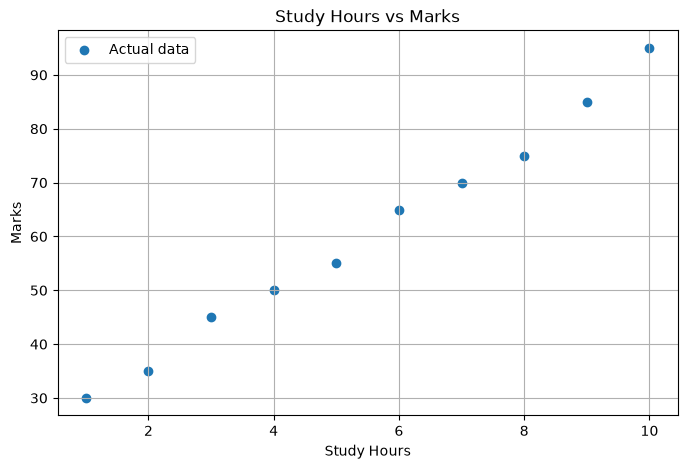

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X["study_hours"],
    y,
    label="Actual data"
)

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Study Hours vs Marks")

plt.legend()
plt.grid(True)

plt.show()

### 2. Regression line

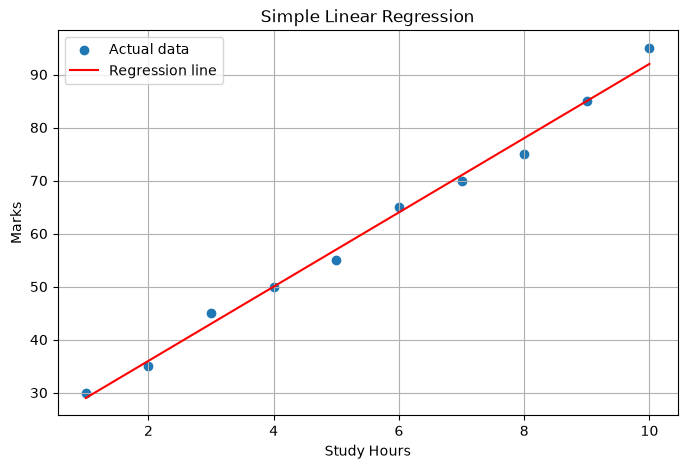

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X["study_hours"],
    y,
    label="Actual data"
)

plt.plot(
    X["study_hours"],
    predictions,
    label="Regression line",
    color="red"
)

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Simple Linear Regression")

plt.legend()
plt.grid()

plt.show()

**Observe:**
- Dots represent actual observations.
- The straight line represents the model's predictions.
- The vertical distance between a dot and the line represents its residual.

## Part 6 — Multiple Linear Regression
So far, we've used only one feature: study hours.

But real-world predictions usually depend on multiple features.

For example, student marks might depend on:
- Study hours.
- Attendance.
- Previous marks.

When Linear Regression uses two or more input features, it is called **Multiple Linear Regression**.

### 1. Mathematical equation
The general equation is:

$$\hat{y}=b_0+b_1x_1+b_2x_2+\cdots+b_nx_n$$

Where:
- $b_0$ = Intercept.
- $b_1,b_2,\ldots,b_n$ = Coefficients.
- $x_1,x_2,\ldots,x_n$ = Input features.

For three features:

$$\hat{y}=b_0+b_1x_1+b_2x_2+b_3x_3$$

Unlike simple regression, the model now learns one coefficient for each feature.

### 2. Create a dataset

In [11]:
student_data = pd.DataFrame({
    "study_hours": [2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
    "attendance": [55, 60, 65, 70, 72, 78, 82, 88, 92, 96],
    "previous_score": [40, 45, 50, 55, 60, 65, 70, 75, 80, 85],
    "final_score": [42, 48, 54, 60, 64, 72, 78, 84, 90, 96]
})

student_data

,study_hours,attendance,previous_score,final_score
0,2,55,40,42
1,3,60,45,48
2,4,65,50,54
3,5,70,55,60
4,6,72,60,64
5,7,78,65,72
6,8,82,70,78
7,9,88,75,84
8,10,92,80,90
9,11,96,85,96


### 3. Separate features and target

In [12]:
X = student_data[["study_hours", "attendance", "previous_score"]]
y = student_data["final_score"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10, 3)
Target shape: (10,)


### 4. Train Multiple Linear Regression

In [13]:
multiple_model = LinearRegression()

multiple_model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.13,0.6 ,0.63]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['study_hours','attendance','previous_score']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-17.07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


### 5. Examine coefficients

In [14]:
print("Intercept:", multiple_model.intercept_)

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": multiple_model.coef_
})

display(coefficients)

Intercept: -17.069027854639316


,Feature,Coefficient
0,study_hours,0.125586
1,attendance,0.604317
2,previous_score,0.627928


Each coefficient represents the predicted change in the target when that feature increases by one unit, holding the other features constant.

For example, if the study-hours coefficient is 2.5, then one additional study hour corresponds to an increase of 2.5 predicted marks, assuming attendance and previous score remain unchanged.

Be careful: coefficients describe the model's learned associations, not necessarily causal effects.

### 6. Predict for a new student

In [15]:
new_student = pd.DataFrame({
    "study_hours": [8],
    "attendance": [85],
    "previous_score": [75]
})

predicted_score = multiple_model.predict(new_student)

print("Predicted final score:", predicted_score[0])

Predicted final score: 82.39719608928242


The model automatically uses all three features to make the prediction.

## Part 7 — Evaluating Regression Models
Let's learn four important regression metrics.
| Metric | Meaning | Better direction |
| :--- | :--- | :--- |
| MAE | Mean Absolute Error | Lower |
| MSE | Mean Squared Error | Lower |
| RMSE | Root Mean Squared Error | Lower |
| R² | Explained variance relative to a mean baseline | Generally closer to 1 |

### 1. MAE — Mean Absolute Error
MAE measures the average absolute difference between actual and predicted values.

$$MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|$$

Example: If the MAE is 4 marks, the average absolute prediction error is 4 marks.

### 2. MSE — Mean Squared Error
MSE squares each prediction error before averaging.

$$MSE=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2$$

Larger errors receive more penalty because of squaring.

### 3. RMSE — Root Mean Squared Error
RMSE is the square root of MSE.

$$RMSE=\sqrt{MSE}$$

It is expressed in the same units as the target variable.

### 4. R² — Coefficient of Determination
R² measures how much variation in the target is explained by the model relative to predicting the mean.

$$R^2=1-\frac{\sum(y_i-\hat{y}_i)^2}
{\sum(y_i-\bar{y})^2}$$

An R² of 0.90 means the model explains 90% of the variation relative to that baseline on the evaluated data.

R² can also be negative, indicating worse performance than that mean-prediction baseline.

### 5. Implement all four metrics

In [16]:
from sklearn.metrics import(
mean_absolute_error,
mean_squared_error,
r2_score
)

y_pred = multiple_model.predict(X)

mae = mean_absolute_error(y, y_pred)
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.34647482014388375
MSE: 0.17419664268585228
RMSE: 0.4173687131133002
R2 Score: 0.9994165439352698


Here, we evaluate on the same data used for training, so these are training metrics, not an unbiased estimate of performance on unseen data. For proper evaluation, use the train-test and cross-validation methods from Day 4.

## Part 8 — Important limitations of Linear Regression
Linear Regression is useful, but it has limitations.
1. It assumes a linear relationship between the target and model coefficients.
2. It can be sensitive to extreme observations.
3. Strong multicollinearity can make individual coefficients unstable.
4. It may perform poorly when relationships are highly nonlinear.
5. It can extrapolate poorly beyond the range of training data.

We'll explore nonlinear relationships and Polynomial Regression in a later lesson.

## Part 9 — Day 5 Quick Revision
| Concept | Remember |
| :--- | :--- |
| Linear Regression | Predicts continuous numerical values |
| Simple Regression | One feature |
| Multiple Regression | Two or more features |
| Coefficient | Change in predicted target per unit feature increase, holding others constant |
| Intercept | Predicted output when all features are zero |
| Residual | Actual value − predicted value |
| Least Squares | Minimizes the sum of squared residuals |
| MAE | Average absolute error |
| MSE | Average squared error |
| RMSE | Square root of MSE |
| R² | Model performance relative to a mean baseline |

# Day 5 assignment 📝
<span style="display: inline-block; background-color: rgba(34, 197, 94, 0.25); color: #22c55e; padding: 1px 12px; border-radius: 9999px; font-size: 13px; font-weight: 600; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; border: 1px solid rgba(34, 197, 94, 0.5);">Practical assignment</span>

We'll use a new dataset: Employee Salary Prediction.

### Dataset creation

In [17]:
import pandas as pd
import numpy as np

data = pd.DataFrame({
    "experience_years": [
        1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
        11, 12, 13, 14, 15, 16, 17, 18, 19, 20
    ],

    "education_years": [
        12, 12, 14, 14, 16, 16, 16, 18, 18, 18,
        16, 18, 18, 20, 20, 20, 18, 20, 20, 22
    ],

    "performance_score": [
        60, 65, 62, 70, 72, 75, 78, 80, 82, 85,
        80, 88, 90, 87, 92, 95, 90, 96, 94, 98
    ],

    "salary_lakhs": [
        3.0, 3.5, 4.0, 4.8, 5.2, 6.0, 6.5, 7.2, 7.8, 8.5,
        8.8, 9.5, 10.2, 10.8, 11.5, 12.2, 12.8, 13.5, 14.2, 15.0
    ]
})

df = data.copy()

df.head()

,experience_years,education_years,performance_score,salary_lakhs
0,1,12,60,3.0
1,2,12,65,3.5
2,3,14,62,4.0
3,4,14,70,4.8
4,5,16,72,5.2


## Task 1 — Dataset exploration
- Inspect shape, columns, data types and missing values.
- Identify the features and target.

In [18]:
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())

print("\nPossible Features:", df.columns[:3].tolist())
print("\nPossible Target:", df.columns[3:].tolist())

Dataset shape: (20, 4)

Columns: ['experience_years', 'education_years', 'performance_score', 'salary_lakhs']

Data types:
experience_years       int64
education_years        int64
performance_score      int64
salary_lakhs         float64
dtype: object

Missing values:
experience_years     0
education_years      0
performance_score    0
salary_lakhs         0
dtype: int64

Possible Features: ['experience_years', 'education_years', 'performance_score']

Possible Target: ['salary_lakhs']


## Task 2 — Simple Linear Regression
- Use experience_years as the only feature.
- Train a Linear Regression model.
- Print its coefficient and intercept.
- Write the mathematical equation.
- Predict salary for 8 years of experience.

In [19]:
from sklearn.linear_model import LinearRegression as lr

X = df[["experience_years"]]
y = df["salary_lakhs"]

model = lr()

model.fit(X, y)

print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Coefficient: 0.6266165413533834
Intercept: 2.1705263157894743


**Understanding your coefficients**
| Parameter | Value | Meaning |
| :--- | :--- | :--- |
| Coefficient (slope) | 0.6266 | Salary increases by approximately ₹0.627 lakh per additional year of experience. |
| Intercept | 2.1705 | The model's estimated salary at zero years of experience. |

The mathematical equation is:

$$\hat{y}=2.1705+0.6266x$$

For 8 years of experience the equation will become:

$$\hat{y}=2.1705+0.6266\times8$$


In [20]:
exp_year = pd.DataFrame({
    "experience_years": [8]
})

predicted_salary = model.predict(exp_year)

print("Predicted salary for 8 years of experience:", predicted_salary[0].round(4), "lakhs")

Predicted salary for 8 years of experience: 7.1835 lakhs


**Prediction review**\
The model predicts: 

$$\hat{y}=2.1705+(0.6266\times8)$$
$$\hat{y}\approx 7.1835$$

So the predicted salary is approximately ₹7.18 lakhs.

## Task 3 — Multiple Linear Regression
- Use all three features.
- Train another Linear Regression model.
- Print the coefficients and intercept.
- Interpret the coefficients.
- Predict salary for a new employee.

In [21]:
X = df[["experience_years",	"education_years", "performance_score"]]
y = df["salary_lakhs"]

multiple_model = lr()

multiple_model.fit(X, y)
print("Intercept:", multiple_model.intercept_)

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficients": multiple_model.coef_
})

display(coefficients)

Intercept: 2.698831614069565


,Feature,Coefficients
0,experience_years,0.642242
1,education_years,0.011327
2,performance_score,-0.010840


**1. Understanding your coefficients**
| Parameter | Value |
| :--- | :--- |
| Intercept | 2.698832 |
| experience_years | +0.642242 |
| education_years | +0.011327 |
| performance_score | -0.010840 |

**2. Understanding the regression equation**
The model learned the following equation:

$$\begin{aligned}
\widehat{salary} ={}& 2.698832\\
&+0.642242E\\
&+0.011327D\\
&-0.010840P
\end{aligned}$$

Where:
- $E$ = experience in years
- $D$ = education in years
- $P$ = performance score

The model uses all three inputs together to estimate salary.

**3. What does each coefficient mean?**\
<span style="color: #FF3333; font-weight: bold;">A. Experience years: +0.642242</span><br>
This is a positive coefficient.

It means:

For every additional year of experience, the predicted salary increases by approximately 0.642242 lakhs, assuming education and performance score remain unchanged.

For example:
- Employee A: 5 years of experience
- Employee B: 6 years of experience

If their education and performance scores are identical, the model predicts that Employee B will earn approximately ₹0.642 lakh more.

<span style="color: #33FF33; font-weight: bold;">B. Education years: +0.011327</span><br>
This is also a positive coefficient.

It means:

For every additional year of education, predicted salary increases by approximately 0.011327 lakhs, assuming experience and performance score remain unchanged.

Converting to rupees:

$$0.011327\times100000=\text{₹ }1,132.70$$

So one additional year of education corresponds to approximately ₹1,133 higher predicted salary.

<span style="color: #3333FF; font-weight: bold;">C. Performance score: -0.010840</span><br>
This is a negative coefficient.

It means:

For every one-point increase in performance score, predicted salary decreases by approximately 0.010840 lakhs, assuming experience and education remain unchanged.

In rupees:

$$0.010840 \times 100000 = \text{₹ }1,084$$

This is a mathematical relationship learned by your model. It does not mean that improving performance actually reduces salary.

Why might this happen?
- Your dataset contains only 20 employees.
- The features may have relationships with one another.
- The model tries to estimate the contribution of each feature while keeping the others constant.

This can produce unexpected coefficient signs.

**4. What is the intercept?**\
The intercept is:

$$b_0 = 2.698832$$

It represents the model's predicted salary when all three features are zero:
- Experience = 0
- Education = 0
- Performance score = 0

Therefore, the predicted salary would be ₹2.698832 lakhs.

However, this combination is probably unrealistic for your dataset. The intercept is primarily the starting value of the mathematical equation.

In [22]:
new_employee = pd.DataFrame({
    "experience_years": [12],
    "education_years": [10],
    "performance_score": [70]
})

prediction = multiple_model.predict(new_employee)

print("Predicted salary:", prediction[0].round(2), "lakhs")

Predicted salary: 9.76 lakhs


**How does the model calculate the prediction?**\
We supplied:
```python
new_employee = pd.DataFrame({
    "experience_years": [12],
    "education_years": [10],
    "performance_score": [70]
})
```
The model substitutes these values into the equation:

$$\begin{aligned}
\widehat{salary}={}&2.698832\\
&+(0.642242\times12)\\
&+(0.011327\times10)\\
&-(0.010840\times70)
\end{aligned}$$

$$\widehat{salary}\approx9.76$$

**Prediction: ₹9.76 lakhs**

<span style="color: #FF3333; font-size: 25px; font-weight: bold;">Important concept: Holding other features constant</span><br>
This is the most important part of interpreting multiple regression coefficients.

Suppose we want to understand the experience coefficient.

We increase experience from 5 to 6 years, but keep education and performance score unchanged.

The predicted salary changes by approximately ₹0.642242 lakhs.

We do this because a multiple regression model considers the contribution of each feature while accounting for the others.

## Task 4 — Visualization
- Create a scatter plot of experience vs salary.
- Plot the simple regression line.
- Label the axes and add a title and legend.

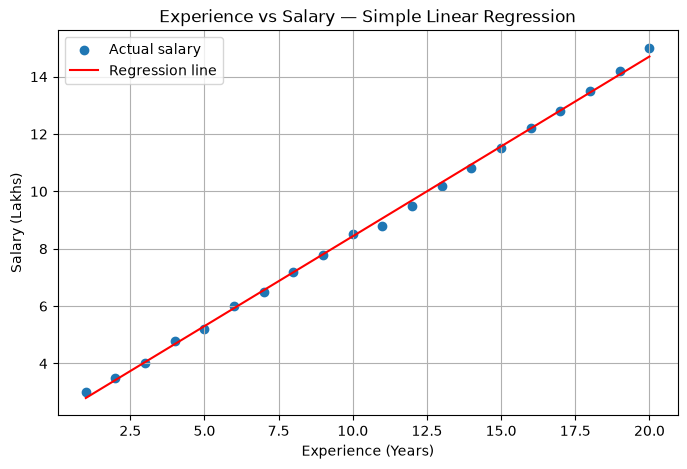

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["experience_years"],
    df["salary_lakhs"],
    label="Actual salary",
    marker="o"
)

plt.plot(
    df["experience_years"],
    model.predict(df[["experience_years"]]),
    label="Regression line",
    color="red"
)

plt.title("Experience vs Salary — Simple Linear Regression")
plt.xlabel("Experience (Years)")
plt.ylabel("Salary (Lakhs)")

plt.legend()
plt.grid()

plt.show()

## Task 5 — Model evaluation
- Split the data into 80% training and 20% testing.
- Calculate MAE, MSE, RMSE and R² for both models on test data.
- Compare the models.

In [24]:
# Simple Linear Model
from sklearn.model_selection import train_test_split as tts
from sklearn.metrics import (
mean_absolute_error,
mean_squared_error,
r2_score
)

X_train, X_test, y_train, y_test = tts(
    df[["experience_years"]],
    df["salary_lakhs"],
    test_size=0.2,
    random_state=42
)

model = lr()

model.fit(X_train, y_train)

train_prediction = model.predict(X_train)
test_prediction = model.predict(X_test)

train_mae = mean_absolute_error(y_train, train_prediction)
test_mae = mean_absolute_error(y_test, test_prediction)

train_mse = mean_squared_error(y_train, train_prediction)
test_mse = mean_squared_error(y_test, test_prediction)

train_rmse = np.sqrt(train_mse)
test_rmse = np.sqrt(test_mse)

train_r2 = r2_score(y_train, train_prediction)
test_r2 = r2_score(y_test, test_prediction)

print("Training MAE:", train_mae)
print("Testing MAE:", test_mae)
print("\nTraining MSE:", train_mse)
print("Testing MSE:", test_mse)
print("\nTraining RMSE:", train_rmse)
print("Testing RMSE:", test_rmse)
print("\nTraining R2:", train_r2)
print("Testing R2:", test_r2)

Training MAE: 0.1051142361634744
Testing MAE: 0.11475644699140408

Training MSE: 0.016867365404916193
Testing MSE: 0.0248309467186168

Training RMSE: 0.12987442167307692
Testing RMSE: 0.15757838277700656

Training R2: 0.9983729556491309
Testing R2: 0.9989334931077584


**Simple Linear Regression results**
| Metric | Training | Testing |
| :--- | :--- | :--- |
| MAE | 0.1051 | 0.1148 |
| MSE | 0.0169 | 0.0248 |
| RMSE | 0.1299 | 0.1576 |
| R² | 0.9984 | 0.9989 |

**MAE — Mean Absolute Error**
- Training error: 0.1051 lakhs
- Testing error: 0.1148 lakhs

On average, the model's predictions differ from actual salaries by approximately ₹10,511 on training data and ₹11,476 on testing data.

**MSE — Mean Squared Error**\
MSE squares each prediction error before averaging it.

The testing MSE is 0.0248.

Larger errors receive a disproportionately greater penalty because of squaring.

**RMSE — Root Mean Squared Error**\
RMSE is the square root of MSE.

The testing RMSE is approximately 0.1576 lakhs, or ₹15,758.

Unlike MSE, RMSE is expressed in the original salary unit.

**R² — Coefficient of Determination**
The testing R² is approximately 0.9989.

This means the model explains approximately 99.89% of the variation in salary on this test set.

**2. What do these results tell us?**\
Three observations:
1. Training and testing errors are both low. The model performs well on both datasets.
2. Testing errors are slightly higher. This is normal because the model was trained on the training data, not the testing data.
3. Training and testing R² are very close. There is no obvious indication of a large generalization gap on this particular split.

In [25]:
# Multiple Linear Model
from sklearn.model_selection import train_test_split as tts
from sklearn.metrics import (
mean_absolute_error,
mean_squared_error,
r2_score
)

X_train, X_test, y_train, y_test = tts(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = lr()

model.fit(X_train, y_train)

train_prediction = model.predict(X_train)
test_prediction = model.predict(X_test)

train_mae = mean_absolute_error(y_train, train_prediction)
test_mae = mean_absolute_error(y_test, test_prediction)

train_mse = mean_squared_error(y_train, train_prediction)
test_mse = mean_squared_error(y_test, test_prediction)

train_rmse = np.sqrt(train_mse)
test_rmse = np.sqrt(test_mse)

train_r2 = r2_score(y_train, train_prediction)
test_r2 = r2_score(y_test, test_prediction)

print("Training MAE:", train_mae)
print("Testing MAE:", test_mae)
print("\nTraining MSE:", train_mse)
print("Testing MSE:", test_mse)
print("\nTraining RMSE:", train_rmse)
print("Testing RMSE:", test_rmse)
print("\nTraining R2:", train_r2)
print("Testing R2:", test_r2)

Training MAE: 0.0988240072119036
Testing MAE: 0.1486643471292839

Training MSE: 0.015539305393730272
Testing MSE: 0.03748915152447555

Training RMSE: 0.12465675029347698
Testing RMSE: 0.19362115464090063

Training R2: 0.9985010617574023
Testing R2: 0.9983898141726844


**1. Multiple Linear Regression results**
| Metric | Training | Testing |
| :--- | :--- | :--- |
| MAE | 0.0988 | 0.1487 |
| MSE | 0.0155 | 0.0375 |
| RMSE | 0.1247 | 0.1936 |
| R² | 0.9985 | 0.9984 |

**MAE — Mean Absolute Error**
- Training error: 0.0988 lakhs
- Testing error: 0.1487 lakhs

On average, the model's predictions differ from actual salaries by approximately ₹9,882 on training data and ₹14,866 on testing data.

**MSE — Mean Squared Error**\
MSE squares each prediction error before averaging it.

The testing MSE is 0.0375.

Larger errors receive a disproportionately greater penalty because of squaring.

**RMSE — Root Mean Squared Error**\
RMSE is the square root of MSE.

The testing RMSE is approximately 0.1936 lakhs, or ₹19,362.

Unlike MSE, RMSE is expressed in the original salary unit.

**R² — Coefficient of Determination**
The testing R² is approximately 0.9984.

This means the model explains approximately 99.84% of the variation in salary on this test set.

**2. What do these results tell us?**\
Three observations:
1. Training and testing errors are both low. The model performs well on both datasets.
2. Testing errors are slightly higher. This is normal because the model was trained on the training data, not the testing data.
3. Training and testing R² are very close. There is no obvious indication of a large generalization gap on this particular split.

**3. Compare both models**\
Here are the testing results from your two models:
| Metric | Simple Regression | Multiple Regression |
| :--- | :--- | :--- |
| MAE | 0.1148 | 0.1487 |
| MSE | 0.0248 | 0.0375 |
| RMSE | 0.1576 | 0.1936 |
| R² | 0.9989 | 0.9984 |

**4. Which model performed better?**\
<span style="color: #33FF33; font-size: 15px;">Simple Linear Regression</span><br>

Based on this particular test split:
- **MAE:** Simple regression has lower average absolute error.
- **MSE:** Simple regression has lower squared error.
- **RMSE:** Simple regression has lower prediction error in the original salary unit.
- **R²:** Simple regression explains slightly more variation in the test data.

Interestingly, our model with just one feature performed better than the model with three features.

This can happen because adding more features does not automatically improve test performance. Additional features may introduce noise or redundant information.

**5. Conclusion:**\
Both Simple and Multiple Linear Regression models performed well on the test dataset. However, Simple Linear Regression achieved lower MAE, MSE and RMSE, along with a slightly higher R² score. Therefore, Simple Linear Regression performed better on this particular test split. This suggests that experience alone captures much of the salary relationship in this dataset.

<span style="color: #FF3333; font-size: 25px; font-weight: bold;">Important:</span><br>
Our dataset has only 20 observations, so this result is specific to this small dataset and split. We shouldn't conclude that simple regression is generally better than multiple regression.

## Task 6 — Prediction (Multiple Linear Regression)
Predict the salary of an employee with 12 years of experience, 18 years of education and a performance score of 90.

In [28]:
new_employee = pd.DataFrame({
    "experience_years": [12],
    "education_years": [18],
    "performance_score": [90]
})

prediction = multiple_model.predict(new_employee)

print("Predicted salary:", prediction[0].round(2), "lakhs")

Predicted salary: 9.63 lakhs


So, the salary of an employee with 12 years of experience, 18 years of education and a performance score of 90 will be around `9.63` lakhs.

## Task 7 — Conceptual questions
1. What is the difference between simple and multiple Linear Regression?
	<div style="padding-left: 5px; margin-top: 2px;">
		<span style="color: #0076B2;">➤</span> The primary difference between simple linear regression and multiple linear regression in machine learning is the number of independent variables (input features) used to predict a single dependent variable (target).
	</div>
<br>

2. What does a coefficient represent?
	<div style="padding-left: 5px; margin-top: 2px;">
		<span style="color: #0076B2;">➤</span> A coefficient represents the expected change in the predicted target value when its corresponding input feature increases by one unit, while keeping all other features constant.
	</div>
<br>

3. What does an intercept represent?
	<div style="padding-left: 5px; margin-top: 2px;">
		<span style="color: #0076B2;">➤</span> The intercept represents the predicted output when all input features are zero. It is the starting value of the regression equation.
	</div>
<br>

4. Why does Linear Regression minimize squared residuals instead of simply minimizing the residuals?

	<div style="padding-left: 5px; margin-top: 2px;">
		<span style="color: #0076B2;">➤</span> Linear Regression minimizes squared residuals to prevent positive and negative errors from cancelling each other out. Squaring also penalizes larger errors more heavily and makes mathematical optimization convenient. This method is called Ordinary Least Squares (OLS).
	</div>
<br>

Residual is the difference between the actual value and the predicted value.

$$Residual = Actual - Predicted$$

Suppose we have three observations:

| Actual salary | Predicted salary | Residual |
| :--- | :--- | :--- |
| 5 | 4 | +1 |
| 8 | 10 | -2 |
| 12 | 11 | +1 |

<br>

**1. Problem with simply adding residuals**\
If we add the residuals:

$$1+(-2)+1=0$$

The result is zero, even though the predictions are not perfect!

Positive and negative residuals cancel each other out.

**2. Solution: Square the residuals**\
Instead, Linear Regression squares every residual:

$$SSE = \sum (Actual-Predicted)^2$$

For our example:

$$SSE = 1^2+(-2)^2+1^2$$
$$SSE=1+4+1=6$$

Now all errors are positive, and larger errors receive a greater penalty.

**3. Three main reasons**
1. **Prevents cancellation:** Squaring makes negative and positive errors positive.
2. **Penalizes large errors:** Larger errors contribute disproportionately more.
3. **Mathematical convenience:** Squared error produces a smooth, differentiable objective that can be efficiently minimized.
<br>

5. What is the difference between MAE and MSE?
	<div style="padding-left: 5px; margin-top: 2px;">
		<span style="color: #0076B2;">➤</span> Key difference:
	</div>

| MAE | MSE |
| :--- | :--- |
| Uses absolute errors | Uses squared errors |
| Less sensitive to large errors | More sensitive to large errors |
| Easier to interpret | Penalizes large errors more heavily |
| Same unit as target | Squared unit of target |

6. Can R² be negative?
	<div style="padding-left: 5px; margin-top: 2px;">
		<span style="color: #0076B2;">➤</span> Yes, R² can be negative when the model performs worse than a baseline model that predicts the mean of the target values. It indicates poor predictive performance.
	For example:
		<ul>
			<li>R² = 1.0 → Perfect predictions.</li>
			<li>R² = 0.85 → Explains 85% of the 
				variation.</li>
			<li>R² = 0 → No improvement over predicting 
				the mean.</li>
			<li>R² = -0.5 → Performs worse than 
				predicting the mean.</li>
		</ul>
	</div>
<br>

7. Why should we be careful when interpreting coefficients?
	<div style="padding-left: 5px; margin-top: 2px;">
		<span style="color: #0076B2;">➤</span> We should be careful when interpreting coefficients because they can misrepresent the strength, direction, or real-world meaning of a relationship. Coefficients do not establish causation, can be affected by correlated features, and depend on the dataset and feature scales.
	</div>
<br>

1. **Correlation is not causation:** A coefficient does not prove that a feature causes a change in the target.

2. **Other features matter:** In Multiple Linear Regression, each coefficient represents the change in predicted output while holding other features constant.

3. **Feature relationships:** Highly correlated features can make coefficients unstable or produce unexpected signs.

4. **Dataset limitations:** Small or biased datasets can produce misleading coefficients.

5. **Feature scales:** Coefficients depend on the units and scales of the input features.

<h1 style="text-align: center; margin-top: 20px; margin-bottom: 20px; color: #f43f5e;">The End of Day 5</h1>